# Solar Filament Segmentation 2026 - full pipeline
Image (H-alpha, 2048x2048) -> U-Net probability map (ResNet34 encoder, 4-flip TTA, model average) -> threshold ->
connected components on a dilated mask -> one RLE per filament -> CSV. Weights are in `models/`; nothing is re-trained here.
Set `DATA` to the unzipped `MAGFiLO_1.0_Kaggle_2026` folder.

In [1]:
%matplotlib inline
import glob, json, os
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
from pycocotools import mask as mu
import fil
from predict import UNet, prep, predict, instances

DATA = glob.glob("**/MAGFiLO_1.0_Kaggle_2026", recursive=True)[0]
dev = "cuda" if torch.cuda.is_available() else "cpu"
cfg = json.load(open("models/ensemble.json"))
print(DATA, dev, [m["file"] for m in cfg["models"]], cfg["postprocess"])

data/raw/MAGFiLO_1.0_Kaggle_2026 cpu ['e80all.pt', 'a2.pt', 'a5.pt'] {'thr': 0.4, 'dil': 15, 'min_area': 300, 'min_max': 0.9, 'min_mean': 0.8}


## 1. Models

In [2]:
def load(m):
    net = UNet().to(dev).eval()
    net.load_state_dict({k: v.float() for k, v in torch.load("models/" + m["file"], map_location=dev, weights_only=True).items()})
    return net, m["res"], m.get("flat", False)

models = [load(m) for m in cfg["models"]]

def prob_map(img, models):
    ps = []
    for net, res, flat in models:  # each model at its own resolution, averaged at 1024
        p = predict(net, prep(img, res, flat), dev)
        ps.append(cv2.resize(p, (1024, 1024), interpolation=cv2.INTER_AREA) if res != 1024 else p)
    return np.mean(ps, 0)

## 2. Look at a few test images (no ground truth is available for them)

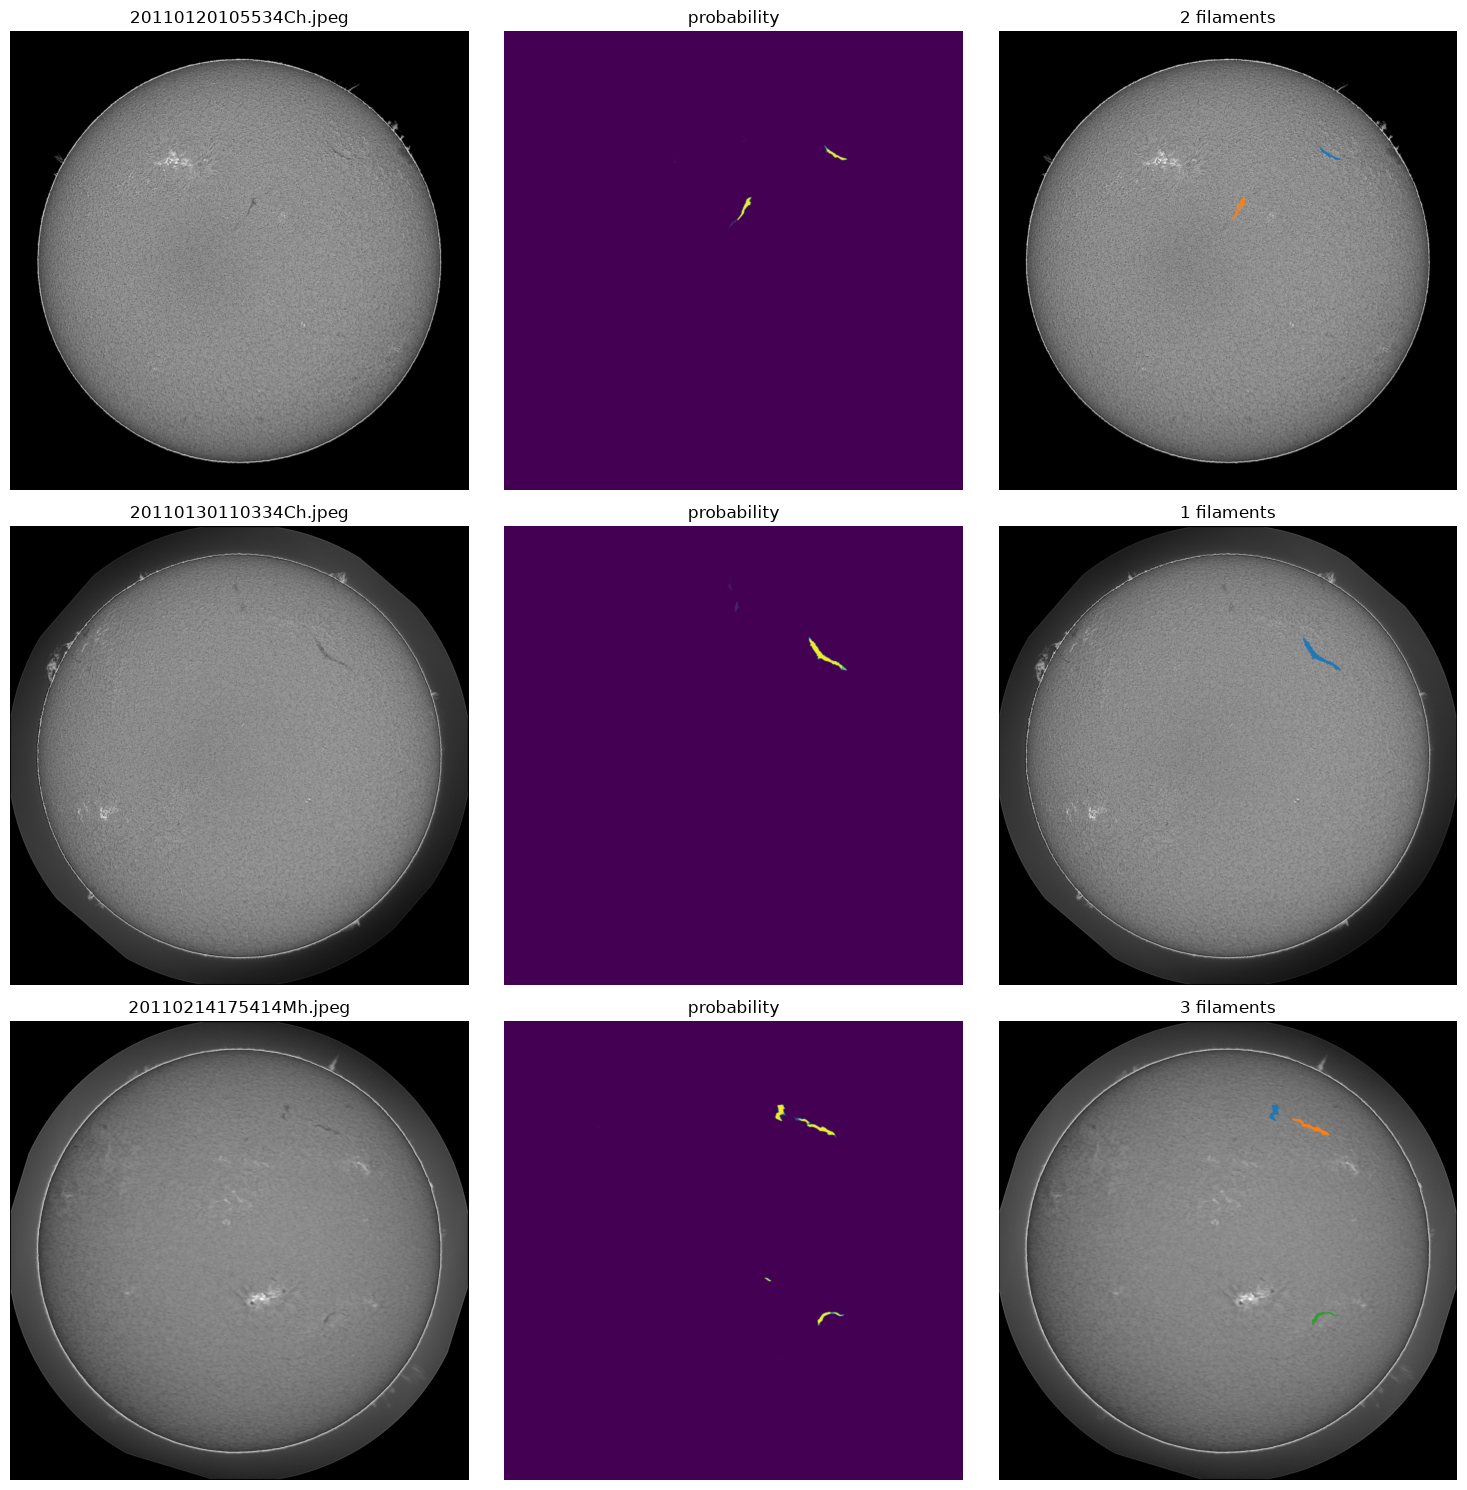

In [3]:
test_dir = f"{DATA}/test/test_images"
files = sorted(os.listdir(test_dir))[:3]
fig, ax = plt.subplots(len(files), 3, figsize=(15, 5 * len(files)), squeeze=False)
for r, f in enumerate(files):
    img = cv2.imread(f"{test_dir}/{f}", cv2.IMREAD_GRAYSCALE)
    p = prob_map(img, models)
    inst = instances(p, **cfg["postprocess"])
    ov = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for i, c in enumerate(inst):
        m = mu.decode({"size": [2048, 2048], "counts": c.encode()})
        ov[m > 0] = np.array(plt.cm.tab10(i % 10)[:3]) * 255
    ax[r, 0].imshow(img, cmap="gray"); ax[r, 1].imshow(cv2.resize(p, (2048, 2048)), vmin=0, vmax=1); ax[r, 2].imshow(ov)
    ax[r, 0].set_title(f); ax[r, 1].set_title("probability"); ax[r, 2].set_title(f"{len(inst)} filaments")
    for a in ax[r]: a.axis("off")
plt.tight_layout()

## 3. Sanity check against ground truth on held-out observations
Uses only the model trained without the last-but-two date block (fold 2) so the images below were never seen in training.
The score is the competition's Panoptic Quality (IoU > 0.5), pooled over every annotator's version of each image.

In [4]:
val_cfg = json.load(open("models/val_check.json"))
val_models = [load(m) for m in val_cfg["models"]]
img_file, anns, by_file = fil.load_train(DATA)
names = sorted(by_file)
holdout = [f for i, f in enumerate(names) if i * 5 // len(names) == 2][:12]  # first 12 of the validation block
pairs = []
for f in holdout:
    img = cv2.imread(f"{DATA}/train/train_images/{f}", cv2.IMREAD_GRAYSCALE)
    pred = [{"size": [2048, 2048], "counts": c.encode()} for c in instances(prob_map(img, val_models), **val_cfg["postprocess"])]
    pairs += [(fil.instance_rles(anns[i]), pred) for i in by_file[f]]
print("PQ on", len(holdout), "held-out images:", round(fil.pq(pairs), 4))

PQ on 12 held-out images: 0.4403


## 4. Full submission
Same as `python predict.py --images ... --config models/ensemble.json --out submission.csv`.

In [5]:
import subprocess, sys
subprocess.run([sys.executable, "predict.py", "--images", test_dir, "--config", "models/ensemble.json", "--out", "submission.csv"], check=True)
print(open("submission.csv").read()[:300])

20110120105534Ch.jpeg


20110130110334Ch.jpeg


20110214175414Mh.jpeg


20110329082654Uh.jpeg


20110408083214Th.jpeg


20110424064534Lh.jpeg


... (171 outputs left out)

20220626185332Bh.jpeg


20220714185352Th.jpeg


20220728185352Th.jpeg
submission.csv 1212 instances


filament_id,segmentation_rle
20110120105534Ch_1,S`bi22no13N1O1O2M3N012M1O00O10O010O101O0O010000O1O1O1O010O10O0010O0100O101O00000O100O100O1O1000O100O2M2O001O0O1O10001O0100O01000O1O01000000O01O10O0100O000001O10O00001O01O1N1O100000000000001O1O0O101N2OV^[P1
20110120105534Ch_2,WjPQ23lo12M2O001O1N100O11OO
